# Demo 3. 프라이버시 공격과 모델 추출
**아주대학교 인공지능 보안 1회차 · 20:00~20:50 세션 데모**

| 단계 | 내용 | 소요 |
|---|---|---|
| 1 | 멤버십 추론 공격 — “이 환자 데이터가 학습에 쓰였나?” | 5분 |
| 2 | 방어 — 과적합 억제·출력 최소화가 공격을 얼마나 약화시키나 | 3분 |
| 3 | 모델 역전(Inversion) — 모델에서 클래스 대표 이미지 복원 | 2분 |
| 4 | 모델 추출 — API 질의만으로 모델 복제 + 탐지 | 5분 |

> 의료 데이터 예시는 `make_classification`으로 만든 **합성 데이터**입니다(실제 개인정보 아님).

In [1]:
# 필요 패키지: numpy, scikit-learn, matplotlib (Colab/Anaconda 기본 포함)
# 로컬 환경에서 없으면: !pip install -q numpy scikit-learn matplotlib
import numpy as np
import matplotlib.pyplot as plt
import warnings; warnings.filterwarnings("ignore")
np.set_printoptions(precision=3, suppress=True)
plt.rcParams["figure.dpi"] = 110
from sklearn.datasets import make_classification, load_digits
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import roc_auc_score, roc_curve
rng = np.random.default_rng(0)

## 1. 멤버십 추론 공격 (Membership Inference)
- 시나리오: 병원이 “합병증 위험 예측 모델” API를 공개. 공격자는 **특정인의 기록**을 갖고 있다.
- 모델이 그 기록에 **유난히 높은 확신도**를 보이면 → “이 사람은 학습 데이터(=해당 병원 환자)에 포함” 추론
- 원리: 과적합된 모델은 **본 적 있는 데이터(member)** 에 더 자신 있게 답한다 (Shokri et al., 2017)

[overfit model] train acc 100.0% | test acc 84.3% | MIA AUC 0.892 | advantage(TPR-FPR) 0.62


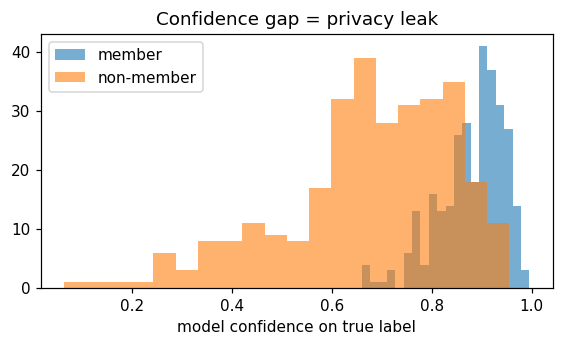

In [2]:
Xm, ym = make_classification(n_samples=2000, n_features=30, n_informative=10, flip_y=0.05, random_state=1)
Xa, Xb, ya, yb = train_test_split(Xm, ym, test_size=0.5, random_state=0)
X_mem, y_mem = Xa[:300], ya[:300]        # 병원 학습 데이터 (member)
X_non, y_non = Xb[:300], yb[:300]        # 학습에 쓰이지 않은 사람 (non-member)

def mia(model, name):
    model.fit(X_mem, y_mem)
    c_in  = model.predict_proba(X_mem)[np.arange(300), y_mem]   # 정답 클래스 확신도
    c_out = model.predict_proba(X_non)[np.arange(300), y_non]
    s, lab = np.r_[c_in, c_out], np.r_[np.ones(300), np.zeros(300)]
    auc = roc_auc_score(lab, s)
    fpr, tpr, _ = roc_curve(lab, s)
    print(f"[{name}] train acc {model.score(X_mem, y_mem):.1%} | test acc {model.score(X_non, y_non):.1%} "
          f"| MIA AUC {auc:.3f} | advantage(TPR-FPR) {np.max(tpr - fpr):.2f}")
    return c_in, c_out, fpr, tpr, auc

over = mia(RandomForestClassifier(200, random_state=0), "overfit model")
plt.figure(figsize=(6, 3))
plt.hist(over[0], bins=20, alpha=.6, label="member"); plt.hist(over[1], bins=20, alpha=.6, label="non-member")
plt.xlabel("model confidence on true label"); plt.legend(); plt.title("Confidence gap = privacy leak"); plt.show()

## 2. 방어: 일반화(정규화) + 출력 최소화
- **과적합 억제**: 트리 깊이 제한, 최소 리프 크기 → train/test 격차 감소
- **출력 최소화**: 확률 대신 레이블만, 또는 소수점 반올림 → 공격자가 쓸 신호 감소
- (심화) **차분 프라이버시(DP-SGD)**: 수학적으로 개인 기여도를 제한 — 2·3회차에서 연계

[regularized] train acc 90.7% | test acc 84.7% | MIA AUC 0.612 | advantage(TPR-FPR) 0.20


[overfit + rounded output] MIA AUC 0.878
[overfit + label-only]   MIA AUC 0.578


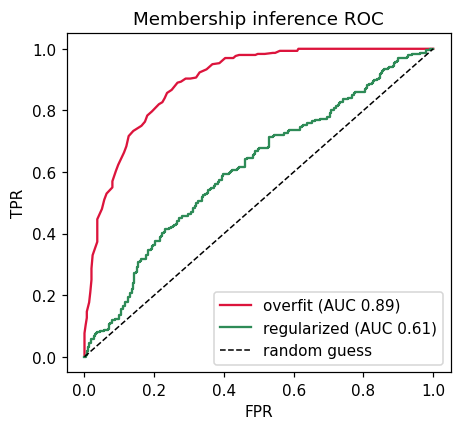

In [3]:
reg = mia(RandomForestClassifier(200, max_depth=4, min_samples_leaf=10, random_state=0), "regularized")

# 출력 최소화: 확률을 0.1 단위로만 공개 (rounding)
m = RandomForestClassifier(200, random_state=0).fit(X_mem, y_mem)
r_in  = np.round(m.predict_proba(X_mem)[np.arange(300), y_mem], 1)
r_out = np.round(m.predict_proba(X_non)[np.arange(300), y_non], 1)
print(f"[overfit + rounded output] MIA AUC {roc_auc_score(np.r_[np.ones(300), np.zeros(300)], np.r_[r_in, r_out]):.3f}")
# 레이블만 공개하면 '맞혔는가' 정보만 남음
l_in, l_out = (m.predict(X_mem) == y_mem), (m.predict(X_non) == y_non)
print(f"[overfit + label-only]   MIA AUC {roc_auc_score(np.r_[np.ones(300), np.zeros(300)], np.r_[l_in, l_out]):.3f}")

plt.figure(figsize=(4.5, 4))
plt.plot(over[2], over[3], label=f"overfit (AUC {over[4]:.2f})", c="crimson")
plt.plot(reg[2], reg[3], label=f"regularized (AUC {reg[4]:.2f})", c="seagreen")
plt.plot([0, 1], [0, 1], "k--", lw=1, label="random guess")
plt.xlabel("FPR"); plt.ylabel("TPR"); plt.legend(); plt.title("Membership inference ROC"); plt.show()

> **강사 포인트**: 레이블만 공개해도 AUC가 0.5가 되지는 않습니다(과적합 자체가 신호). **근본 대책은 일반화와 DP**, 출력 제한은 보조 수단.

## 3. 모델 역전 (Model Inversion)
모델의 기울기를 따라 **“이 클래스일 확률이 최대가 되는 입력”** 을 역으로 찾으면 학습 데이터의 평균적 특징이 드러납니다.
(Fredrikson et al., 2015 — 얼굴 인식 모델에서 얼굴 복원) 여기서는 숫자 분류 모델로 시연합니다.

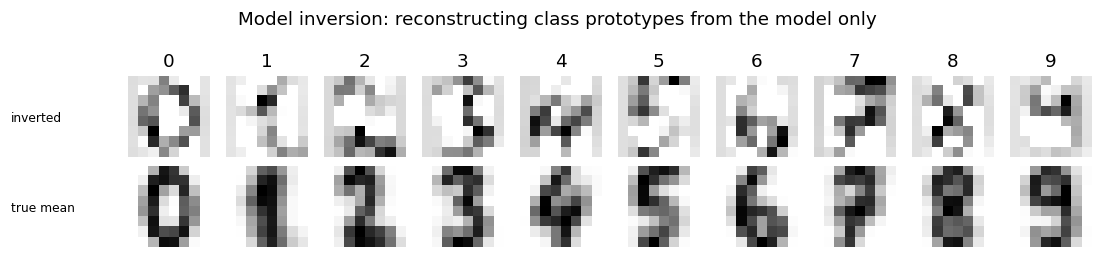

In [4]:
Xd, yd = load_digits(return_X_y=True); Xd = Xd / 16.0
def softmax(z): z = z - z.max(1, keepdims=True); e = np.exp(z); return e / e.sum(1, keepdims=True)
# 간단한 softmax 모델 학습
W, b, Y = np.zeros((64, 10)), np.zeros(10), np.eye(10)[yd]
for _ in range(300):
    P = softmax(Xd @ W + b); W -= 0.5 * (Xd.T @ (P - Y) / len(Xd) + 1e-3 * W); b -= 0.5 * (P - Y).mean(0)

recon = []
for c in range(10):
    x = np.full((1, 64), 0.3)
    for _ in range(200):                       # 경사 상승: log p(c|x) 최대화 + 작은 L2 정규화
        p = softmax(x @ W + b)
        g = (np.eye(10)[[c]] - p) @ W.T - 0.05 * x
        x = np.clip(x + 0.1 * g, 0, 1)
    recon.append(x[0])

fig, ax = plt.subplots(2, 10, figsize=(10, 2.4))
for c in range(10):
    ax[0, c].imshow(recon[c].reshape(8, 8), cmap="gray_r"); ax[0, c].set_title(c); ax[0, c].axis("off")
    ax[1, c].imshow(Xd[yd == c].mean(0).reshape(8, 8), cmap="gray_r"); ax[1, c].axis("off")
ax[0, 0].text(-12, 4, "inverted", fontsize=8); ax[1, 0].text(-12, 4, "true mean", fontsize=8)
plt.suptitle("Model inversion: reconstructing class prototypes from the model only"); plt.tight_layout(); plt.show()

## 4. 모델 추출 (Model Extraction / Stealing)
- 시나리오: 경쟁사가 유료 예측 API에 **질의 → 응답(레이블)** 을 수집해 대리 모델을 학습 (Tramèr et al., 2016)
- 측정 지표: **충실도(Fidelity)** = 대리 모델과 원본 모델의 예측 일치율
- 공격자는 원본 학습 데이터 없이 **비슷한 분포의 공개 데이터(unlabeled)** 만 보유했다고 가정

queries=25   fidelity (public-like data) 70.2% | (random noise) 24.4%


queries=50   fidelity (public-like data) 79.6% | (random noise) 18.7%


queries=100  fidelity (public-like data) 90.6% | (random noise) 24.4%


queries=200  fidelity (public-like data) 92.6% | (random noise) 30.1%


queries=400  fidelity (public-like data) 95.3% | (random noise) 28.1%


queries=600  fidelity (public-like data) 96.7% | (random noise) 37.1%


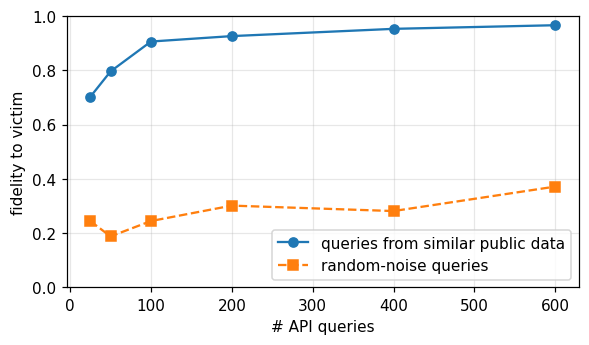

In [5]:
D_vic, D_rest, y_vic, y_rest = train_test_split(Xd, yd, test_size=0.5, random_state=0, stratify=yd)
D_pool, D_eval = D_rest[:600], D_rest[600:]          # 공격자 질의용 공개 데이터 / 평가용

victim = MLPClassifier((128,), max_iter=800, random_state=0).fit(D_vic, y_vic)
query_log = []                                       # 서비스 측 API 로그
def predict_api(x, client="attacker"):
    query_log.append((client, len(x)))
    return victim.predict(x)                         # 레이블만 반환해도 추출 가능

budgets = [25, 50, 100, 200, 400, 600]
fid_nat, fid_rand = [], []
for n in budgets:
    q = D_pool[:n]
    sur = MLPClassifier((128,), max_iter=800, random_state=0).fit(q, predict_api(q))
    fid_nat.append((sur.predict(D_eval) == victim.predict(D_eval)).mean())
    qr = rng.uniform(0, 1, (n, 64))                  # 데이터가 전혀 없는 공격자: 무작위 질의
    sur_r = MLPClassifier((128,), max_iter=800, random_state=0).fit(qr, predict_api(qr))
    fid_rand.append((sur_r.predict(D_eval) == victim.predict(D_eval)).mean())
    print(f"queries={n:<4} fidelity (public-like data) {fid_nat[-1]:.1%} | (random noise) {fid_rand[-1]:.1%}")

plt.figure(figsize=(6, 3.2))
plt.plot(budgets, fid_nat, "o-", label="queries from similar public data")
plt.plot(budgets, fid_rand, "s--", label="random-noise queries")
plt.xlabel("# API queries"); plt.ylabel("fidelity to victim"); plt.ylim(0, 1); plt.grid(alpha=.3); plt.legend(); plt.show()

### 추출 공격 탐지·완화
1. **질의량 제한(Rate limit / 과금)**: 위 곡선에서 질의 예산이 작을수록 충실도 하락
2. **질의 분포 이상 탐지**: 정상 사용자 입력과 거리가 먼 질의(무작위 노이즈 등) 비율을 모니터링 (PRADA, Juuti et al., 2019 아이디어)
3. **출력 최소화**·워터마킹, 호출 주체 인증·인가와 주체별 감사 로그 (→ AWS: API Gateway IAM·Cognito·Lambda 권한 부여자로 인증·인가, API 키·사용량 계획으로 사용량 추적·제한(최선형 적용), CloudTrail·모델 호출 로깅)

In [6]:
from sklearn.neighbors import NearestNeighbors
ref = NearestNeighbors(n_neighbors=1).fit(D_vic)
thr = np.percentile(ref.kneighbors(D_pool[:200])[0], 99)        # 정상 질의의 99% 분위수를 임계값으로

def ood_ratio(batch): return (ref.kneighbors(batch)[0][:, 0] > thr).mean()
normal_user  = D_eval[:100]
noise_attack = rng.uniform(0, 1, (100, 64))
print(f"OOD ratio  normal user: {ood_ratio(normal_user):.0%}  |  random-query attacker: {ood_ratio(noise_attack):.0%}")
print(f"API log - total queries by attacker: {sum(n for c, n in query_log if c == 'attacker')}  -> rate-limit/alert 대상")

OOD ratio  normal user: 1%  |  random-query attacker: 100%
API log - total queries by attacker: 2750  -> rate-limit/alert 대상


## 정리 (슬라이드로 복귀)
| 공격 | 노리는 것 | 핵심 신호 | 대표 대응 |
|---|---|---|---|
| 멤버십 추론 | 특정인의 학습 데이터 포함 여부 | 과적합 → 확신도 격차 | 정규화, DP, 출력 최소화 |
| 모델 역전 | 학습 데이터의 특징 복원 | 기울기·확률 정보 | 출력 최소화, 접근 통제 |
| 모델 추출 | 모델 기능(지적재산) | 대량 질의 응답 | 인증·Rate limit, 질의 모니터링, 워터마킹 |